# PanEcho – EchoNet-Dynamic Preprocessing

This notebook prepares a **separate PanEcho manifest** from the original EchoNet `FileList.csv`. It does not overwrite your existing project manifest. Run the cells from top to bottom.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Find the ml-service folder automatically
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Open this notebook from inside your ml-service project.")
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "echo" / "echonet"
VIDEOS_DIR = RAW_DIR / "Videos"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "echo" / "echonet"
PANECHO_MANIFEST_PATH = PROCESSED_DIR / "echonet_panecho_manifest.csv"

print("Project:", PROJECT_ROOT)
print("Raw EchoNet:", RAW_DIR)
print("Videos:", VIDEOS_DIR)

Project: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service
Raw EchoNet: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\raw\echo\echonet
Videos: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\raw\echo\echonet\Videos


In [3]:
# Check that the original EchoNet files are present
filelist_path = RAW_DIR / "FileList.csv"
tracings_path = RAW_DIR / "VolumeTracings.csv"

for name, path in {
    "FileList.csv": filelist_path,
    "VolumeTracings.csv": tracings_path,
    "Videos folder": VIDEOS_DIR,
}.items():
    print(f"{name:20}: {'FOUND' if path.exists() else 'MISSING'}")

if not filelist_path.exists() or not VIDEOS_DIR.exists():
    raise FileNotFoundError("EchoNet data is incomplete. Check data/raw/echo/echonet/")

FileList.csv        : FOUND
VolumeTracings.csv  : FOUND
Videos folder       : FOUND


In [4]:
# Read the original dataset information
filelist = pd.read_csv(filelist_path)
print("Original videos in FileList.csv:", len(filelist))
print("Columns:", filelist.columns.tolist())
display(filelist.head())

if tracings_path.exists():
    tracings = pd.read_csv(tracings_path)
    print("VolumeTracings rows:", len(tracings))
else:
    print("VolumeTracings.csv not found. It is not needed for EF/EDV/ESV regression.")

Original videos in FileList.csv: 10030
Columns: ['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


VolumeTracings rows: 425010


In [5]:
# Create a PanEcho manifest using ALL available FileList records
# Keep the official TRAIN / VAL / TEST split.

def get_video_path(file_name):
    file_name = str(file_name).strip()
    if Path(file_name).suffix.lower() != ".avi":
        file_name += ".avi"
    return VIDEOS_DIR / file_name

video_paths = filelist["FileName"].apply(get_video_path)
manifest = pd.DataFrame({
    "video_name": filelist["FileName"].astype(str),
    "video_path": [p.relative_to(PROJECT_ROOT).as_posix() for p in video_paths],
    "EF": pd.to_numeric(filelist["EF"], errors="coerce"),
    "EDV": pd.to_numeric(filelist["EDV"], errors="coerce"),
    "ESV": pd.to_numeric(filelist["ESV"], errors="coerce"),
    "num_frames": pd.to_numeric(filelist["NumberOfFrames"], errors="coerce"),
    "split": filelist["Split"].astype(str).str.strip().str.lower().replace({"validation": "val"}),
})

# Remove only rows whose actual video file is missing; print the number removed.
manifest["video_exists"] = video_paths.apply(lambda p: p.is_file())
missing_count = int((~manifest["video_exists"]).sum())
print("Videos missing from Videos folder:", missing_count)
manifest = manifest[manifest["video_exists"]].drop(columns="video_exists").reset_index(drop=True)

allowed_splits = {"train", "val", "test"}
unknown_splits = set(manifest["split"].dropna().unique()) - allowed_splits
if unknown_splits:
    raise ValueError(f"Unexpected split names: {unknown_splits}")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
manifest.to_csv(PANECHO_MANIFEST_PATH, index=False)
print("Saved PanEcho manifest:", PANECHO_MANIFEST_PATH)
print("Usable videos:", len(manifest))
display(manifest.head())

Videos missing from Videos folder: 8500
Saved PanEcho manifest: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\processed\echo\echonet\echonet_panecho_manifest.csv
Usable videos: 1530


,video_name,video_path,EF,EDV,ESV,num_frames,split
0,0X100009310A3BD7FC,data/raw/echo/echonet/Videos/0X100009310A3BD7F...,78.498406,69.210534,14.881368,174,val
1,0X1002E8FBACD08477,data/raw/echo/echonet/Videos/0X1002E8FBACD0847...,59.101988,98.742884,40.383876,215,train
2,0X1005D03EED19C65B,data/raw/echo/echonet/Videos/0X1005D03EED19C65...,62.363798,37.909734,14.267784,104,train
3,0X10075961BC11C88E,data/raw/echo/echonet/Videos/0X10075961BC11C88...,54.545097,72.914210,33.143084,122,train
4,0X10094BA0A028EAC3,data/raw/echo/echonet/Videos/0X10094BA0A028EAC...,24.887742,169.855024,127.581945,207,val


In [6]:
# Check split sizes and available labels
print("Videos per split:")
print(manifest["split"].value_counts())

print("\nAvailable labels per split:")
print(manifest.groupby("split")[["EF", "EDV", "ESV"]].count())

print("\nMean EF per split:")
print(manifest.groupby("split")["EF"].mean())

Videos per split:
split
train    1144
val       204
test      182
Name: count, dtype: int64

Available labels per split:
         EF   EDV   ESV
split                  
test    182   182   182
train  1144  1144  1144
val     204   204   204

Mean EF per split:
split
test     56.752408
train    56.292427
val      55.816417
Name: EF, dtype: float64


In [7]:
# Decode one video and check the PanEcho input format
from src.datasets.panecho_echonet_dataset import load_echonet_records
from src.preprocessing.echo.panecho_transforms import PanEchoClipTransform, clip_indices, clip_starts
from src.echo_processing.panecho_reader import decode_video

records = load_echonet_records(
    manifest=PANECHO_MANIFEST_PATH,
    project_root=PROJECT_ROOT,
)

row = records.iloc[0]
frames, video_info = decode_video(row["video_path"], max_frames=256)
start = clip_starts(len(frames), clip_len=16, num_clips=1)[0]
indices = clip_indices(start, len(frames), clip_len=16)
clip = PanEchoClipTransform(train=False)(np.stack([frames[i] for i in indices]))

print("Video:", row["video_path"])
print("Video information:", video_info)
print("PanEcho input shape:", tuple(clip.shape))
print("Expected shape: (3, 16, 224, 224)")

Video: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\raw\echo\echonet\Videos\0X100009310A3BD7FC.avi
Video information: {'fps': 50.0, 'reported_frames': 174, 'decoded_frames': 174, 'source_width': 112, 'source_height': 112}
PanEcho input shape: (3, 16, 224, 224)
Expected shape: (3, 16, 224, 224)


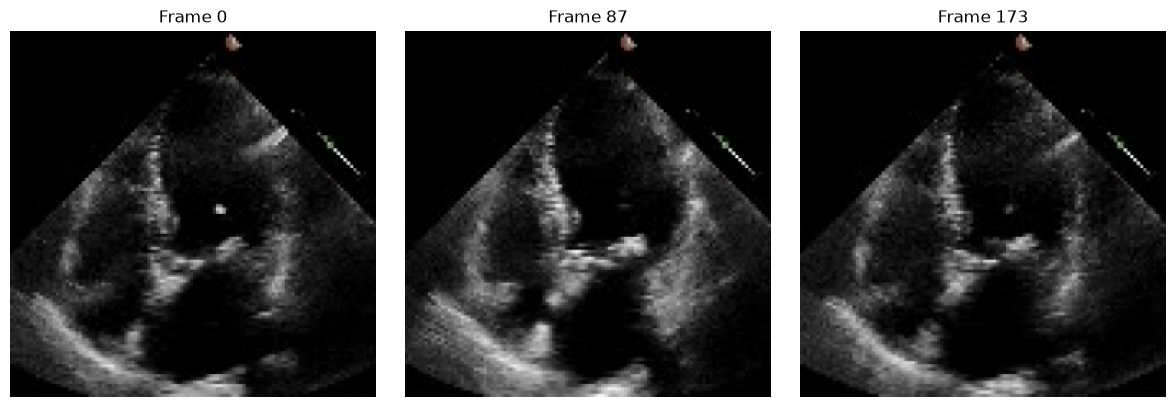

In [8]:
# View a few frames from the decoded video
frame_ids = [0, len(frames) // 2, len(frames) - 1]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, frame_id in zip(axes, frame_ids):
    ax.imshow(cv2.cvtColor(frames[frame_id], cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {frame_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()